# Orientation — What satellite data is available, and what can we do with it?

This notebook is Step 1 of the **monsoon-resilient crop monitoring** project.
It teaches the core ideas using **real data** over the Cauvery Delta, Tamil Nadu.

By the end you will understand:
1. What STAC is and how to search the free Planetary Computer catalog.
2. Why Sentinel-2 optical data collapses during the Indian monsoon.
3. What Sentinel-1 SAR gives us that optical cannot.
4. How to load a real scene and compute a vegetation index (NDVI).

Run with: `jupyter notebook`, then open this file. Kernel = the project `.venv`.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import stackstac

from sentinel_tool.config import AOI_BBOX, AOI_NAME, SEASON_WINDOW, S1_GRD_COLLECTION, S2_COLLECTION
from sentinel_tool.stac import open_catalog, search_items
from sentinel_tool.indices import ndvi

## 1. STAC in 60 seconds

**STAC** (SpatioTemporal Asset Catalog) is a standard way to ask: *"give me all images
over this box, in this date range, from this sensor."* Planetary Computer exposes a
free STAC API. No account needed for the data we use.

In [2]:
catalog = open_catalog()
collections = {c.id: c for c in catalog.get_collections()}
print(f"Available collections: {len(collections)}")
for key in ["sentinel-2-l2a", "sentinel-1-grd", "sentinel-1-rtc", "esa-worldcover",
            "copernicus-dem-30m", "sentinel-5p-l2-netcdf"]:
    print(" -", key, "OK" if key in collections else "(not on PC)")

Available collections: 139
 - sentinel-2-l2a OK
 - sentinel-1-grd OK
 - sentinel-1-rtc OK
 - esa-worldcover OK
 - copernicus-dem-30m (not on PC)
 - sentinel-5p-l2-netcdf OK


## 2. The monsoon cloud gap

Each Sentinel-2 item carries an `eo:cloud_cover` percentage. Sentinel-1 (radar) has
no such concept — it sees through cloud. Let's compare monthly counts of **usable**
optical scenes (<20% cloud) against radar scenes.

In [3]:
s2 = list(search_items(S2_COLLECTION, datetime_=SEASON_WINDOW))
s1 = list(search_items(S1_GRD_COLLECTION, datetime_=SEASON_WINDOW))
print(f"AOI: {AOI_NAME}  bbox={AOI_BBOX}")
print(f"S2 scenes: {len(s2)} | S1 scenes: {len(s1)}")

rows = [{"month": i.datetime.strftime("%Y-%m"), "sensor": "S2",
         "cloud": i.properties.get("eo:cloud_cover")} for i in s2]
rows += [{"month": i.datetime.strftime("%Y-%m"), "sensor": "S1", "cloud": np.nan} for i in s1]
df = pd.DataFrame(rows)

summary = []
for (month, sensor), g in df.groupby(["month", "sensor"]):
    usable = (g.cloud < 20).sum() if sensor == "S2" else len(g)
    summary.append({"month": month, "sensor": sensor,
                    "scenes": len(g), "usable": usable,
                    "median_cloud_%": round(g.cloud.median(), 1) if sensor == "S2" else None})
tbl = pd.DataFrame(summary).pivot(index="month", columns="sensor")
tbl

AOI: Cauvery Delta, Tamil Nadu  bbox=(79.0, 10.8, 79.5, 11.2)
S2 scenes: 180 | S1 scenes: 16


scenes     usable     median_cloud_%      
sensor      S1  S2     S1  S2             S1    S2
month                                             
2025-06      6  44      6  17            NaN  35.5
2025-07      4  48      4  14            NaN  61.6
2025-08      4  44      4   4            NaN  94.7
2025-09      2  44      2   3            NaN  91.1

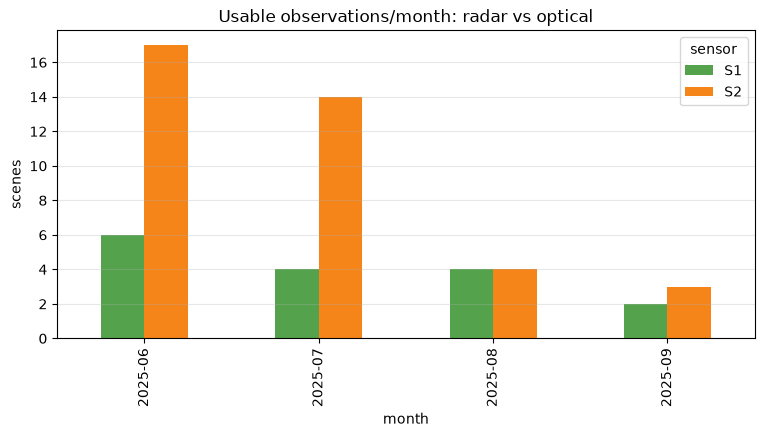

In [4]:
tbl["usable"].plot(kind="bar", figsize=(9, 4), color=["#54A24B", "#F58518"])
plt.title("Usable observations/month: radar vs optical")
plt.ylabel("scenes")
plt.grid(axis="y", alpha=.3)
plt.show()

**Look at Aug–Sep:** ~44 optical scenes are *acquired* but only ~3–4 are usable.
That is the gap our toolkit exists to close by fusing in radar.

## 3. Load a real scene and compute NDVI

Sentinel-2 L2A bands are surface reflectance scaled by 10,000. We pick the
clearest scene, stack a few bands with `stackstac`, clip to the AOI, and compute
**NDVI = (NIR − Red) / (NIR + Red)** — a proxy for crop greenness/vigour.

In [5]:
item = min(s2, key=lambda it: it.properties.get("eo:cloud_cover", 100))
print("Scene:", item.id, "| cloud:", round(item.properties["eo:cloud_cover"], 1), "%")

bands = ["B02", "B03", "B04", "B08", "B11"]
cube = stackstac.stack([item], assets=bands, bounds_latlon=AOI_BBOX,
                       epsg=32644, resolution=20, chunksize=1024)
scene = cube.sel(band=bands).isel(time=0).compute() / 10_000.0
blue, green, red, nir, swir = (scene.sel(band=b) for b in bands)
nd = ndvi(red, nir)

Scene: S2C_MSIL2A_20250820T051051_R019_T44PKT_20250820T102116 | cloud: 0.3 %


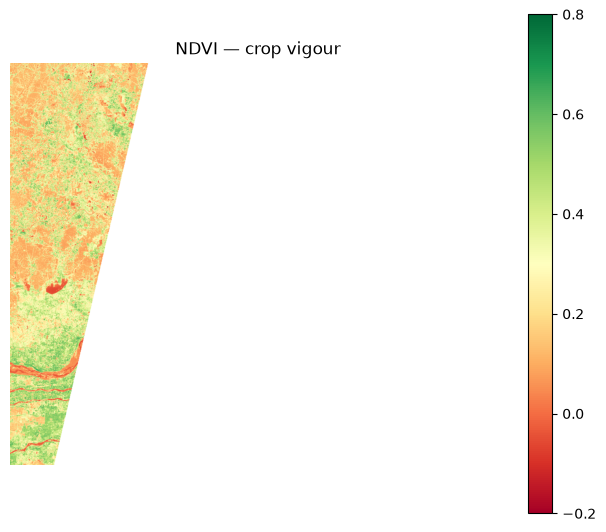

NDVI range: -0.23491900539714236 to 0.708599018480196


In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(nd, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
ax.set_title("NDVI — crop vigour")
ax.set_axis_off()
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()
print("NDVI range:", float(nd.min()), "to", float(nd.max()))

## 4. What we can build from here

- **Indices:** NDVI (vigour), NDRE (nitrogen), NDWI (water) from Sentinel-2 bands.
- **Radar metrics:** VV/VH backscatter and change from Sentinel-1 — works through cloud.
- **Fusion (our core primitive):** combine S1 + S2 into a cloud-free time series.
- **Analytics:** per-field zonal stats, phenology curves, anomaly/stress alerts.
- **Next verticals:** flood extent (S1), water bodies (NDWI), land-use change.

**Next step (Stage 2):** build the aligned S1+S2 fusion cube that fills the monsoon gaps.